# 02 - Character-level Huffman source coding
**Objective.** Compress sentences into bits with a variable-length prefix code built from training statistics, and verify that decoding is lossless.

**Concept.** Huffman coding gives frequent characters short code words. The expected length $\bar L$ satisfies $H \le \bar L < H+1$ where $H=-\sum p_i\log_2 p_i$ is the source entropy (bits/char). **Efficiency** $=H/\bar L$. A fixed-length code would need $\lceil\log_2 |V|\rceil$ bits/char.
Characters never seen in training map to a reserved `UNK` symbol (reconstructed as U+FFFD) so encoding never fails.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # project root = import root
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
print("project root:", ROOT)

project root: /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1


In [2]:
from task1_conventional.dataset import load_split
from task1_conventional.huffman import HuffmanCodec, UNK_CHAR
train, test = load_split("train", ROOT / "data"), load_split("test", ROOT / "data")
codec = HuffmanCodec.from_corpus(train)            # TRAINING DATA ONLY
codec.save(ROOT / "data/processed/huffman_codebook.json")
print("vocabulary (incl. UNK):", codec.vocab_size)

vocabulary (incl. UNK): 85


## 1. Code words

,char,freq,code,length
0,SP,309477,111,3
1,e,190211,001,3
2,t,132328,1011,4
3,a,118279,1001,4
4,o,112719,0111,4
5,n,102666,0110,4
6,i,102208,0101,4
7,s,96033,0001,4
8,r,89686,0000,4
9,h,81952,11010,5


,char,freq,code,length
81,[,1,01001001010001011001,20
82,+,1,01001001010001011000,20
83,],1,01001001010001011010,20
84,UNK,1,01001001010001011011,20


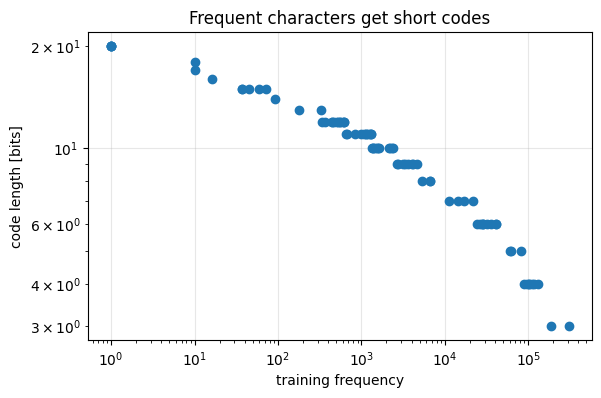

In [3]:
cb = pd.DataFrame({"char": [repr(c)[1:-1] if c not in (" ", UNK_CHAR) else ("SP" if c == " " else "UNK") for c in codec.code],
                   "freq": [codec.freq[c] for c in codec.code], "code": list(codec.code.values())})
cb["length"] = cb.code.str.len(); cb = cb.sort_values("freq", ascending=False).reset_index(drop=True)
display(cb.head(12)); display(cb.tail(4))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(cb.freq, cb.length, "o"); ax.set_xlabel("training frequency"); ax.set_ylabel("code length [bits]")
ax.set_title("Frequent characters get short codes"); plt.show()

## 2. Lossless round trip on multiple sentences

In [4]:
for s in test[:3]:
    b = codec.encode(s); r = codec.decode(b)
    print(f"{len(s):3d} chars -> {len(b):3d} bits | ok={r == s} | {''.join(map(str, b[:40]))}...")
rep = codec.verify_lossless(test); print(rep)
assert rep["mismatches"] == 0
tr_rep = codec.verify_lossless(train[:5000]); print("first 5000 training sentences:", tr_rep)
print("unknown-char handling:", repr(codec.decode(codec.encode("caf\u00e9"))))

 80 chars -> 372 bits | ok=True | 0100101110000100110100011110001101110011...
 89 chars -> 386 bits | ok=True | 0100101101001010101111100100011110111110...
114 chars -> 482 bits | ok=True | 0100000010111110101000111101011100101000...
{'n_sentences': 2000, 'mismatches': 0, 'unknown_chars': 0}
first 5000 training sentences: {'n_sentences': 5000, 'mismatches': 0, 'unknown_chars': 0}
unknown-char handling: 'caf�'


## 3. Efficiency

In [5]:
res = {
 "entropy H [bit/char] (training pmf)": codec.entropy(),
 "average code length [bit/char] (training pmf)": codec.average_length(),
 "efficiency H / L": codec.efficiency(),
 "measured bits/char on TEST set": codec.empirical_length(test),
 f"fixed-length code ceil(log2 {codec.vocab_size})": codec.fixed_length(),
}
r = pd.Series(res, name="value").to_frame(); display(r)
bits_per_sentence = np.array([len(codec.encode(s)) for s in test])
print("test sentence: mean %.1f bits, min %d, max %d" % (bits_per_sentence.mean(), bits_per_sentence.min(), bits_per_sentence.max()))
print("compression vs fixed-length: %.1f %%" % (100 * (1 - res["measured bits/char on TEST set"] / codec.fixed_length())))
r.to_csv(TAB / "huffman_statistics.csv")

,value
entropy H [bit/char] (training pmf),4.469507
average code length [bit/char] (training pmf),4.498280
efficiency H / L,0.993604
measured bits/char on TEST set,4.491450
fixed-length code ceil(log2 85),7.000000


test sentence: mean 322.1 bits, min 126, max 591
compression vs fixed-length: 35.8 %


**Take-away.** The code is within a fraction of a bit of the entropy and compresses ~36 % relative to a fixed-length code. Because Huffman output is *highly compressed*, every residual bit error is damaging: a single flipped bit desynchronises the prefix code and garbles the characters that follow. This is the root of the cliff effect studied in notebook 09.